# London Airbnb Market Analysis | Python Portfolio Project
**Dataset:** User-provided `listingss.csv` (69,351 rows, 18 fields; dataset file dated October 2022).  
**Goal:** Understand listing supply, advertised nightly prices, room types, host concentration, reviews, and availability across London boroughs.

> **Learning notebook:** Every code section explains *what it does* and *why it matters*. Run from top to bottom. This is an independent London analysis inspired by an Airbnb project tutorial, not a reproduction of its unverified steps.

**Important:** Prices are advertised nightly prices, not realised bookings or revenue. Availability is a snapshot, not occupancy. Reviews are not bookings. This dataset is historical and should not be described as the current London market.

## 1. Setup — import libraries
- `pandas` (`pd`) loads and groups tabular data.
- `numpy` (`np`) helps with numerical calculations.
- `matplotlib.pyplot` (`plt`) draws charts.
- `Path` creates portable file locations.

Install dependencies if needed: `pip install pandas numpy matplotlib jupyter nbformat`.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})
DATA_PATH = Path("listingss.csv")
assert DATA_PATH.exists(), "Put listingss.csv in the same folder as this notebook."

## 2. Load and inspect the data
`read_csv` converts the CSV into a **DataFrame** (a table). `shape` reports rows and columns, `head()` previews records, and `info()` shows data types and missing values.

In [3]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head(5))
df.info()

Rows, columns: (69351, 18)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license
0,106332,"Lovely large room, Bethnal Green",264345,Susie,NaN,Tower Hamlets,51.52874,-0.05396,Private room,55,3,65,2016-06-10,0.47,1,74,0,NaN
1,13913,Holiday London DB Room Let-on going,54730,Alina,NaN,Islington,51.56861,-0.11270,Private room,50,1,30,2022-07-15,0.20,2,343,9,NaN
2,284532,COSY STUDIO-FLAT WITH A GREAT VIEW,1481412,Luca,NaN,Tower Hamlets,51.52851,-0.07426,Entire home/apt,90,5,42,2022-01-04,0.34,1,222,1,NaN
3,107048,A Luxury Studio Suite in Clerkenwell,259088,Simon,NaN,Islington,51.52478,-0.10484,Private room,180,4,493,2022-09-02,3.59,5,236,20,NaN
4,284603,Notting Hill church stay in Heaven!,1481851,Tania,NaN,Kensington and Chelsea,51.51464,-0.20004,Entire home/apt,297,14,6,2022-07-04,0.05,1,180,2,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69351 entries, 0 to 69350
Data columns (total 18 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              69351 non-null  int64  
 1   name                            69330 non-null  object 
 2   host_id                         69351 non-null  int64  
 3   host_name                       69346 non-null  object 
 4   neighbourhood_group             0 non-null      float64
 5   neighbourhood                   69351 non-null  object 
 6   latitude                        69351 non-null  float64
 7   longitude                       69351 non-null  float64
 8   room_type                       69351 non-null  object 
 9   price                           69351 non-null  int64  
 10  minimum_nights                  69351 non-null  int64  
 11  number_of_reviews               69351 non-null  int64  
 12  last_review                     

## 3. Data quality checks
`isna().sum()` counts missing values in each column. `duplicated(subset=["id"])` checks repeated listing IDs. We keep a report before cleaning, so changes are auditable.

In [4]:
quality = pd.DataFrame({"missing_count": df.isna().sum(), "missing_pct": df.isna().mean().mul(100).round(1), "dtype": df.dtypes.astype(str)})
display(quality)
print("Duplicate listing IDs:", df.duplicated(subset=["id"]).sum())
print("Prices <= 0:", (df["price"] <= 0).sum())
print("Price percentiles (£):")
print(df["price"].quantile([0, .25, .5, .75, .95, .99, 1]))

,missing_count,missing_pct,dtype
id,0,0.0,int64
name,21,0.0,object
host_id,0,0.0,int64
host_name,5,0.0,object
neighbourhood_group,69351,100.0,float64
neighbourhood,0,0.0,object
latitude,0,0.0,float64
longitude,0,0.0,float64
room_type,0,0.0,object
price,0,0.0,int64


Duplicate listing IDs: 0
Prices <= 0: 19
Price percentiles (£):
0.00        0.0
0.25       55.0
0.50      100.0
0.75      180.0
0.95      499.0
0.99     1570.0
1.00    25000.0
Name: price, dtype: float64


## 4. Clean the dataset
- `drop_duplicates` keeps one record per listing ID.
- Remove columns that are **100% missing** (they cannot contribute information).
- `to_numeric(..., errors="coerce")` converts malformed numeric values into missing values.
- Exclude non-positive prices from **price analysis only**, without silently discarding listings from supply counts.
- Keep missing reviews missing: zero reviews per month and unknown reviews per month are not necessarily the same thing.
- **Outliers:** For readable *price comparisons*, use the 1st–99th percentile of positive prices. We explicitly label this trimmed subset; it is not the entire market.

In [5]:
clean = df.drop_duplicates(subset=["id"]).copy()
empty_columns = clean.columns[clean.isna().all()].tolist()
clean = clean.drop(columns=empty_columns)
for column in ["price", "minimum_nights", "availability_365", "number_of_reviews", "reviews_per_month"]:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")
clean["last_review"] = pd.to_datetime(clean["last_review"], errors="coerce")
clean["name"] = clean["name"].fillna("Unknown listing")
clean["host_name"] = clean["host_name"].fillna("Unknown host")
valid_prices = clean.loc[clean["price"].gt(0) & clean["price"].notna(), "price"]
lower, upper = valid_prices.quantile([.01, .99])
priced = clean.loc[clean["price"].between(lower, upper)].copy()
print("Dropped entirely empty columns:", empty_columns)
print("All listings:", len(clean), "| Price analysis listings:", len(priced))
print(f"Price comparison range: £{lower:,.0f}–£{upper:,.0f}")

Dropped entirely empty columns: ['neighbourhood_group', 'license']
All listings: 69351 | Price analysis listings: 68438
Price comparison range: £20–£1,570


## 5. London market snapshot
`nunique()` counts distinct boroughs and hosts; `median()` is less sensitive to unusually expensive listings than `mean()`. All listing counts refer to deduplicated records.

In [6]:
summary = pd.Series({"Listings": len(clean), "Boroughs": clean["neighbourhood"].nunique(), "Hosts": clean["host_id"].nunique(), "Median advertised price (£), trimmed": priced["price"].median(), "Median availability (days/year)": clean["availability_365"].median()})
display(summary.to_frame("Value"))

,Value
Listings,69351.0
Boroughs,33.0
Hosts,45229.0
"Median advertised price (£), trimmed",100.0
Median availability (days/year),32.0


## 6. Where are the most Airbnb listings?
`groupby()` creates groups by borough, `size()` counts rows, `sort_values()` ranks them. This is **listing supply**, not guest demand.

,listings
neighbourhood,
Westminster,7763
Tower Hamlets,5595
Hackney,5168
Camden,4707
Kensington and Chelsea,4612
Southwark,3968
Islington,3790
Lambeth,3719
Wandsworth,3473


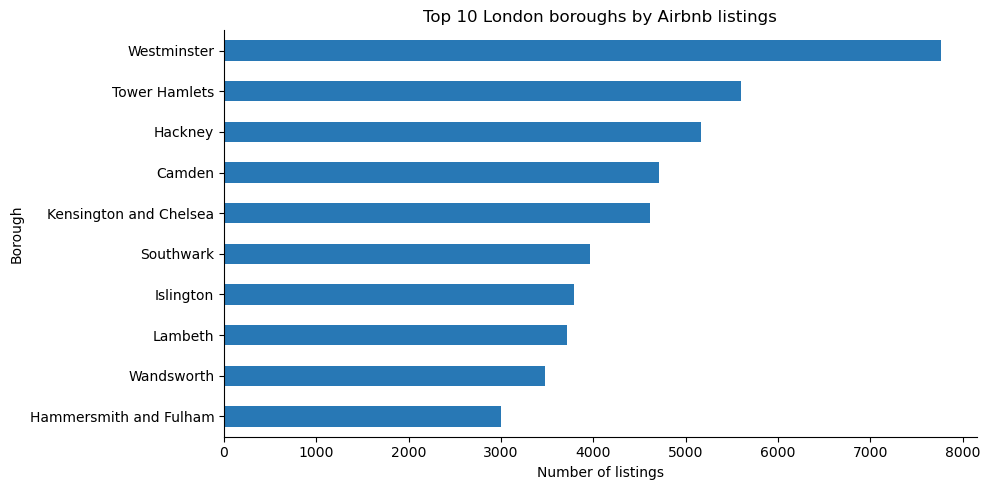

In [7]:
top_boroughs = clean.groupby("neighbourhood").size().sort_values(ascending=False).head(10)
display(top_boroughs.rename("listings").to_frame())
ax = top_boroughs.sort_values().plot.barh(color="#2878b5")
ax.set(title="Top 10 London boroughs by Airbnb listings", xlabel="Number of listings", ylabel="Borough")
plt.tight_layout(); plt.show()

## 7. Which boroughs have higher typical prices?
To avoid tiny samples dominating the ranking, compare boroughs with **at least 100 listings in the trimmed price sample**. `agg` calculates both the count and median. These are advertised prices, not transactions.

,listings,median_price,mean_price
neighbourhood,,,
City of London,421,196.0,237.6
Kensington and Chelsea,4530,182.5,257.7
Westminster,7655,176.0,258.9
Camden,4676,124.0,170.6
Hammersmith and Fulham,2964,110.0,161.8
Richmond upon Thames,1096,100.0,143.1
Wandsworth,3435,99.0,143.1
Islington,3754,99.0,132.0
Southwark,3937,95.0,187.9


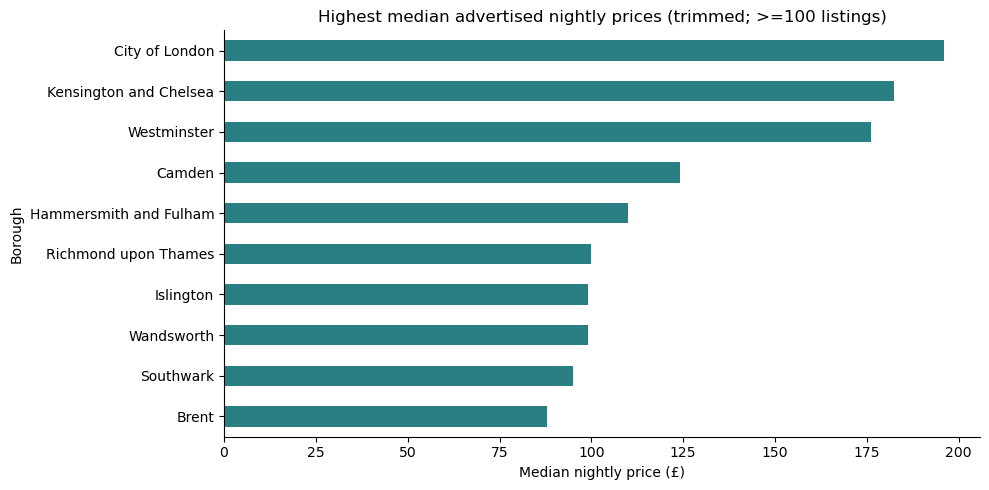

In [8]:
borough_prices = (priced.groupby("neighbourhood")["price"]
                  .agg(listings="size", median_price="median", mean_price="mean")
                  .query("listings >= 100").sort_values("median_price", ascending=False))
display(borough_prices.head(10).round(1))
ax = borough_prices.head(10).sort_values("median_price")["median_price"].plot.barh(color="#297f83")
ax.set(title="Highest median advertised nightly prices (trimmed; >=100 listings)", xlabel="Median nightly price (£)", ylabel="Borough")
plt.tight_layout(); plt.show()

## 8. Room types and prices
`value_counts()` counts room categories. A box plot shows the median and spread of prices; outliers are hidden **in the chart only** for readability. The plotted data already use the explicitly trimmed price sample.

,listings
room_type,
Entire home/apt,41224
Private room,27479
Shared room,404
Hotel room,244


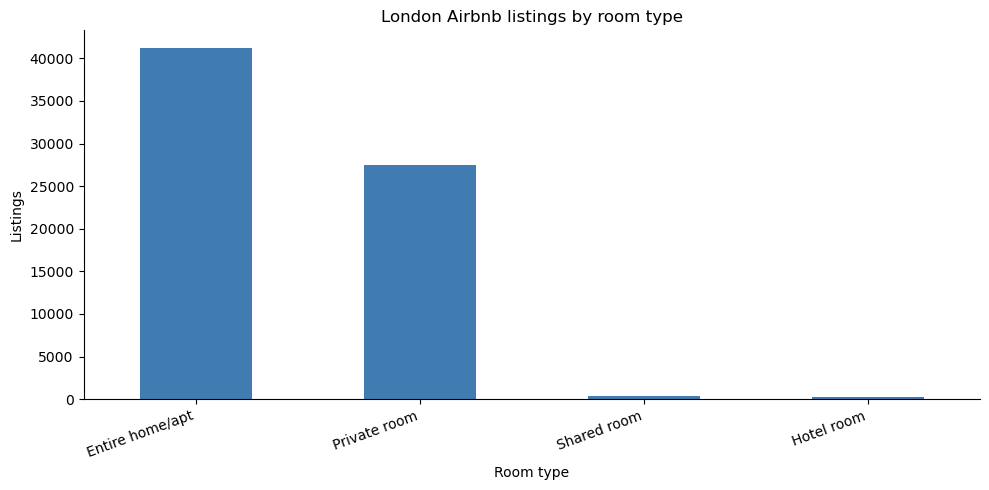

TypeError: Axes.boxplot() got an unexpected keyword argument 'tick_labels'

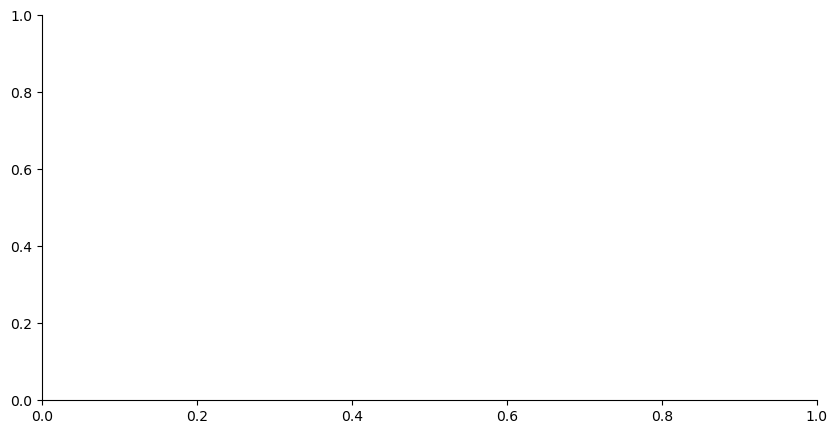

In [ ]:
room_counts = clean["room_type"].value_counts()
display(room_counts.rename("listings").to_frame())
ax = room_counts.plot.bar(color="#407cb2")
ax.set(title="London Airbnb listings by room type", xlabel="Room type", ylabel="Listings")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
room_order = priced.groupby("room_type")["price"].median().sort_values().index.tolist()
fig, ax = plt.subplots()
ax.boxplot([priced.loc[priced["room_type"].eq(r), "price"] for r in room_order], labels=room_order, showfliers=False)
ax.set(title="Advertised nightly price by room type (trimmed)", ylabel="Nightly price (£)")
plt.xticks(rotation=15, ha="right"); plt.tight_layout(); plt.show()

## 9. Price distribution
A histogram divides prices into bins. The median line gives a useful reference point. The shape can be skewed, which is why the median is often more informative than the mean.

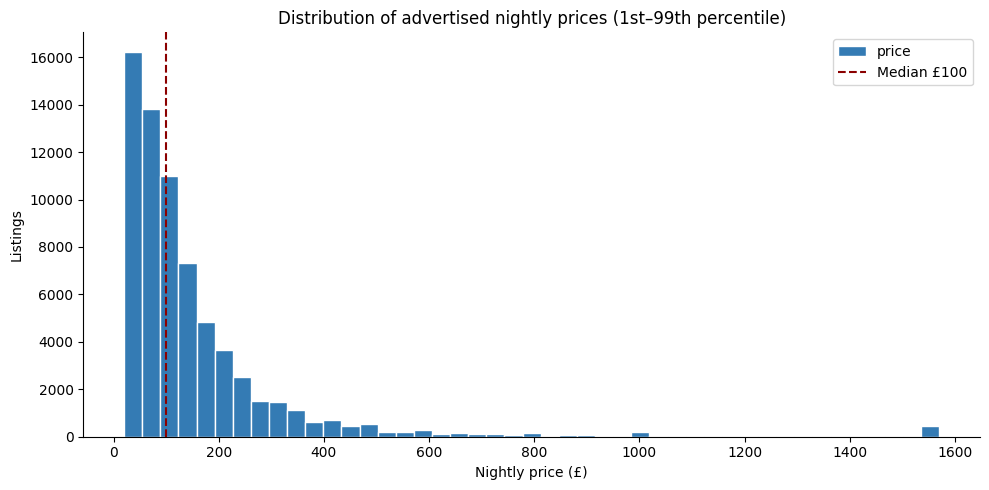

In [9]:
ax = priced["price"].plot.hist(bins=45, color="#347bb4", edgecolor="white")
ax.axvline(priced["price"].median(), color="darkred", linestyle="--", label=f"Median £{priced['price'].median():.0f}")
ax.set(title="Distribution of advertised nightly prices (1st–99th percentile)", xlabel="Nightly price (£)", ylabel="Listings")
ax.legend(); plt.tight_layout(); plt.show()

## 10. Availability and reviews
`availability_365` means days marked available in the next 365 days at the time of data collection; it **does not equal vacancy or occupancy**. Review counts measure reviews, not total stays. We compare typical values across room types.

,listings,median_available_days,median_reviews,median_minimum_nights
room_type,,,,
Entire home/apt,41224,40.0,4.0,3.0
Hotel room,244,275.0,7.0,1.0
Private room,27479,14.0,4.0,2.0
Shared room,404,89.0,1.0,1.0


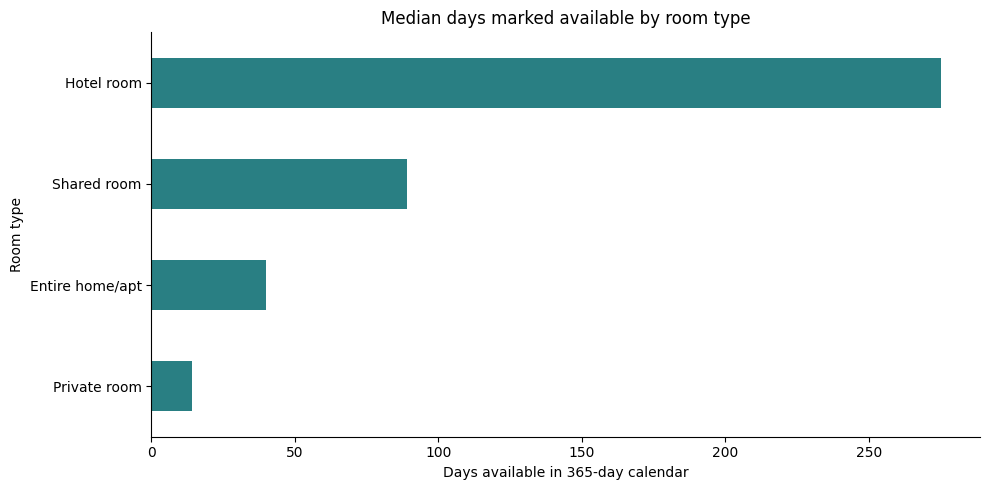

In [10]:
room_metrics = clean.groupby("room_type").agg(listings=("id", "size"), median_available_days=("availability_365", "median"), median_reviews=("number_of_reviews", "median"), median_minimum_nights=("minimum_nights", "median"))
display(room_metrics)
ax = room_metrics["median_available_days"].sort_values().plot.barh(color="#297f83")
ax.set(title="Median days marked available by room type", xlabel="Days available in 365-day calendar", ylabel="Room type")
plt.tight_layout(); plt.show()

## 11. Host concentration
Count how many listing IDs belong to each `host_id`. This shows the distribution of **listings per host in this dataset**, not whether hosts own the properties.

In [11]:
host_counts = clean.groupby("host_id").size().sort_values(ascending=False)
print("Hosts with more than one listing:", int((host_counts > 1).sum()))
print("Share of listings associated with top 10 hosts (%):", round(host_counts.head(10).sum() / len(clean) * 100, 2))
display(host_counts.head(10).rename("listings").to_frame())

Hosts with more than one listing: 7724
Share of listings associated with top 10 hosts (%): 2.73


,listings
host_id,
28820321,285
33889201,266
129230780,259
314162972,189
1432477,168
48165024,165
224866971,157
258154594,148
156158778,127


## 12. Price versus reviews
Scatter plots can reveal patterns, but they **cannot prove causation**. A random sample keeps the figure readable. `random_state=42` makes the sample reproducible.

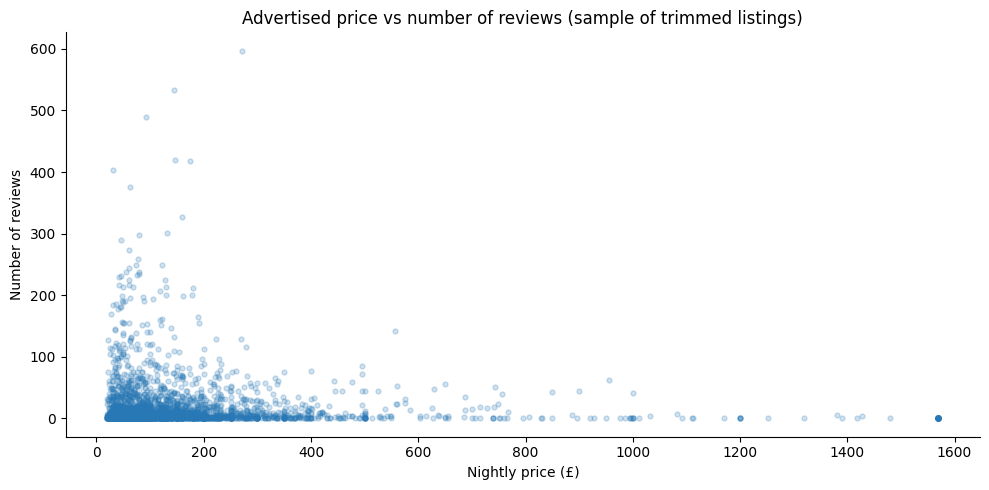

In [12]:
sample = priced.sample(n=min(3000, len(priced)), random_state=42)
fig, ax = plt.subplots()
ax.scatter(sample["price"], sample["number_of_reviews"], alpha=.22, s=13, color="#2878b5")
ax.set(title="Advertised price vs number of reviews (sample of trimmed listings)", xlabel="Nightly price (£)", ylabel="Number of reviews")
plt.tight_layout(); plt.show()

## 13. Export useful tables
`to_csv(index=False)` saves a CSV without an extra row-number column. These outputs are optional supporting files for GitHub. They can be regenerated from this notebook.

In [13]:
OUTPUT = Path("outputs")
OUTPUT.mkdir(exist_ok=True)
top_boroughs.rename("listings").to_csv(OUTPUT / "top_10_boroughs.csv")
borough_prices.to_csv(OUTPUT / "borough_price_comparison.csv")
room_metrics.to_csv(OUTPUT / "room_type_metrics.csv")
print("Saved three reproducible summary tables in outputs/")

Saved three reproducible summary tables in outputs/


## 14. Key findings — automatically calculated
The statements below use the computed results rather than hard-coded claims. They distinguish supply from demand and advertised price from realised revenue.

In [14]:
most_listings = top_boroughs.index[0]
priciest = borough_prices.index[0]
most_common_room = room_counts.index[0]
print(f"• {most_listings} has the largest number of listings in this snapshot ({top_boroughs.iloc[0]:,}).")
print(f"• {priciest} has the highest median advertised nightly price among boroughs with at least 100 listings in the trimmed price sample (£{borough_prices.iloc[0]['median_price']:,.0f}).")
print(f"• The most common room type is {most_common_room} ({room_counts.iloc[0]:,} listings).")
print(f"• The trimmed sample's median advertised nightly price is £{priced['price'].median():,.0f}.")

• Westminster has the largest number of listings in this snapshot (7,763).
• City of London has the highest median advertised nightly price among boroughs with at least 100 listings in the trimmed price sample (£196).
• The most common room type is Entire home/apt (41,224 listings).
• The trimmed sample's median advertised nightly price is £100.


## 15. Limitations and next steps
1. **Snapshot, not a time series:** This dataset does not establish trends across years.
2. **Price is advertised, not booked:** No verified revenue or occupancy conclusions.
3. **Outlier sensitivity:** Price results use a clearly disclosed 1st–99th percentile filter; report this when sharing insights.
4. **Missing reviews:** Do not equate null reviews-per-month with zero.
5. **Host counts:** Multiple listings do not establish ownership.

**Portfolio improvements:** Add a London borough map, compare median prices by room type within boroughs, write 3–5 business takeaways, and include chart screenshots in your GitHub README.

**Interview explanation:** “I used Python and Pandas to clean and validate a London Airbnb listing snapshot, explored pricing and supply by borough and room type, and communicated findings through reproducible Matplotlib charts. I explicitly distinguished advertised price from revenue and availability from occupancy.”